# Proyecto 3: Mejorando algoritmos con CUDA

**CC3069 — Computación Paralela y Distribuida, UVG, Semestre II 2026**

Integrantes: Fernando Ruíz, Olivier Viau, Jose López.

Este informe toma la solución secuencial del **Laboratorio 3 de Data Science
(CC3084)** — un clasificador de letras del alfabeto ASL, dataset [ASL
Alphabet de Kaggle](https://www.kaggle.com/datasets/grassknoted/asl-alphabet)
— desarrollada originalmente por Hugo Barillas, Jose López y Luis Palacios en
[Hugo2049/Laboratorio-3-data-science](https://github.com/Hugo2049/Laboratorio-3-data-science),
y la acelera usando CUDA, midiendo la mejora real de rendimiento al mover la
carga computacional del entrenamiento hacia la GPU.

Todo el código reutilizable vive en `src/` (`data_prep.py`, `model.py`,
`train.py`, `benchmark.py`); este notebook corre ese código y documenta el
análisis, los resultados y la discusión.

In [1]:
import json
import os
import sys
import time

sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import pandas as pd

TRAIN_DIR = "../data/archive/asl_alphabet_train/asl_alphabet_train/"

## Paso 1: Análisis de la solución secuencial

### Partes principales del programa original (`Laboratorio3_ASL.ipynb`)

| # | Parte | Función |
|---|-------|---------|
| 1 | Carga de rutas y muestreo | Lista las 29 clases, toma 600 imágenes/clase (17,400 en total) y arma el DataFrame de rutas + etiquetas |
| 2 | Split train/val/test | `train_test_split` estratificado 70/15/15 sobre las rutas |
| 3 | Carga y preprocesamiento | Lee cada imagen de disco, la redimensiona 200x200 → 64x64 y normaliza a [0,1] |
| 4 | Definición de modelos | Arquitecturas Keras: CNN1, CNN2, red fully-connected |
| 5 | Entrenamiento | `model.fit` — forward pass, pérdida, backward pass, actualización de pesos, por batch y por época |
| 6 | Evaluación | `model.evaluate` / `predict` sobre validación, prueba y fotos propias |

### Operaciones que se ejecutan repetidamente

| Operación repetitiva | Datos que procesa | Cantidad de repeticiones |
|---|---|---|
| Lectura + resize + normalización de una imagen | 1 imagen JPEG 200x200x3 → arreglo 64x64x3 | 17,400 (600 imágenes × 29 clases) |
| Forward pass de un batch | Tensor (batch_size, 64, 64, 3) a través de 3 bloques conv + densas | (12,180 / batch_size) × épocas |
| Backward pass de un batch | Gradientes de la pérdida respecto a todos los pesos | (12,180 / batch_size) × épocas |
| Convolución 2D dentro de un bloque | Cada filtro sobre cada posición espacial del mapa de activación | filtros × alto × ancho × canales de entrada, por batch, por época |

Con `batch_size=32` y 10 épocas sobre 12,180 imágenes de entrenamiento, el
forward+backward se repite ≈ 381 veces por época (≈ 3,810 veces en total), y
cada pasada dispara internamente millones de multiplicaciones en las
convoluciones — esa es la operación que realmente justifica usar GPU.

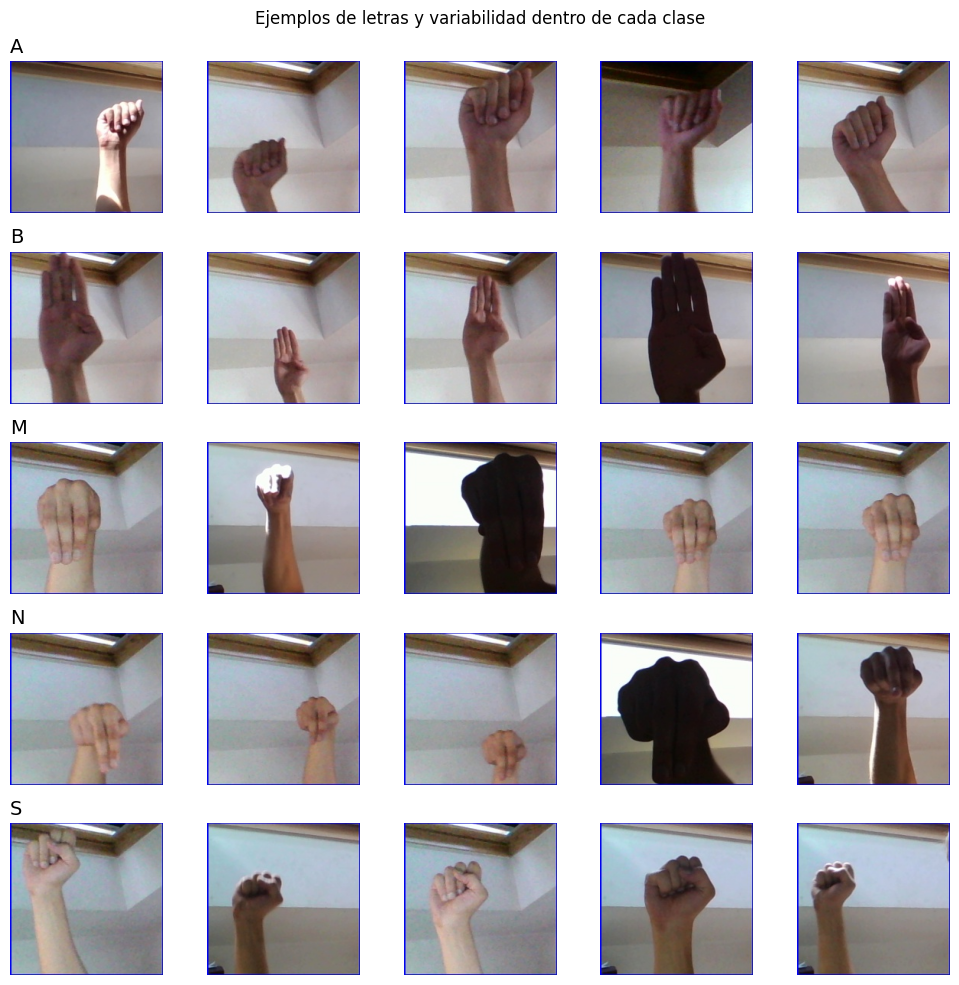

In [2]:
# Ejemplos de letras y variabilidad dentro de una clase (igual que en el Lab 3,
# para que este informe sea legible sin tener que abrir el notebook original)
import random
from matplotlib.image import imread

random.seed(42)
letras_ejemplo = ["A", "B", "M", "N", "S"]
muestras_por_letra = 5

fig, axes = plt.subplots(len(letras_ejemplo), muestras_por_letra, figsize=(10, 10))
for i, letra in enumerate(letras_ejemplo):
    archivos = os.listdir(TRAIN_DIR + letra)
    seleccion = random.sample(archivos, muestras_por_letra)
    for j, archivo in enumerate(seleccion):
        imagen = imread(TRAIN_DIR + letra + "/" + archivo)
        axes[i, j].imshow(imagen)
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(letra, fontsize=14, loc="left")
plt.suptitle("Ejemplos de letras y variabilidad dentro de cada clase")
plt.tight_layout()
plt.show()

In [3]:
# Confirmacion de que el dataset esta balanceado (29 clases x 3000 imagenes)
clases = sorted(os.listdir(TRAIN_DIR))
conteo = {c: len(os.listdir(TRAIN_DIR + c)) for c in clases}
conteo = pd.Series(conteo).sort_index()
print("Clases:", len(clases))
print(conteo.describe())

Clases: 29
count      29.0
mean     3000.0
std         0.0
min      3000.0
25%      3000.0
50%      3000.0
75%      3000.0
max      3000.0
dtype: float64


El análisis exploratorio completo (distribución de clases, letras que se
confunden visualmente M/N/S y U/V/R, definición del split, preprocesamiento,
los 2 CNNs, la red fully-connected, el Random Forest, data augmentation,
pruebas con fotos propias y la reflexión de accesibilidad) ya se hizo en el
Laboratorio 3 y no se repite aquí: este proyecto se enfoca en la
**paralelización con CUDA** de esa solución. Ver el informe completo del
laboratorio en
[laboratorio_3_data.pdf](https://github.com/Hugo2049/Laboratorio-3-data-science)
y el notebook original `Laboratorio3_ASL.ipynb` del mismo repositorio.

## Paso 2: Medición del tiempo de ejecución secuencial

Se ejecutó el pipeline completo (preparación de imágenes + entrenamiento de
la CNN2, que fue el mejor modelo del Lab 3: 3 bloques convolucionales +
dropout) corriendo **todo en CPU**, como baseline secuencial, usando
`python -m src.benchmark`. Los resultados de la última corrida quedaron
guardados en `results/benchmark_resultados.json`.

In [4]:
with open("../results/benchmark_resultados.json", encoding="utf-8") as f:
    resultados = json.load(f)

resultados

{'prep_cpu_secuencial_s': 28.666346900000008,
 'prep_cpu_multinucleo_s': 17.92494479999999,
 'speedup_prep': 1.5992432456472625,
 'entrenamiento_cpu_s': 433.3505812000001,
 'entrenamiento_gpu_s': 16.405707800000073,
 'speedup_entrenamiento': 26.414622671750752,
 'gpu_nombre': 'NVIDIA GeForce RTX 4060 Laptop GPU'}

In [5]:
tabla_tiempos = pd.DataFrame({
    "Fase": ["Preparación de imágenes", "Entrenamiento CNN2 (10 épocas)"],
    "CPU secuencial (s)": [resultados["prep_cpu_secuencial_s"], resultados["entrenamiento_cpu_s"]],
    "Paralelo (s)": [resultados["prep_cpu_multinucleo_s"], resultados["entrenamiento_gpu_s"]],
    "Hardware paralelo": ["CPU multi-núcleo (4 procesos)", resultados.get("gpu_nombre", "GPU CUDA")],
})
tabla_tiempos["Speedup"] = tabla_tiempos["CPU secuencial (s)"] / tabla_tiempos["Paralelo (s)"]
tabla_tiempos

,Fase,CPU secuencial (s),Paralelo (s),Hardware paralelo,Speedup
0,Preparación de imágenes,28.666347,17.924945,CPU multi-núcleo (4 procesos),1.599243
1,Entrenamiento CNN2 (10 épocas),433.350581,16.405708,NVIDIA GeForce RTX 4060 Laptop GPU,26.414623


**Factores que influyen en el tiempo de la fase secuencial:**
- La preparación de imágenes está dominada por I/O de disco (abrir 17,400
  archivos JPEG) y la decodificación/resize de cada una con Pillow — es un
  trabajo repetitivo pero independiente por imagen.
- El entrenamiento secuencial en CPU está dominado por las convoluciones:
  cada capa `Conv2D` recorre todos los filtros sobre todas las posiciones
  espaciales del mapa de activación, para cada imagen de cada batch, en
  cada una de las 10 épocas — multiplicaciones de punto flotante que en CPU
  se ejecutan en gran parte de forma secuencial (pocos núcleos realmente
  usados por operación, comparado con los miles de núcleos CUDA de un GPU).

## Paso 3: Identificación de oportunidades de paralelización

| Operación | ¿Paralelizable? | ¿Dónde? | Justificación |
|---|---|---|---|
| Carga/resize/normalización de imágenes | Sí, entre imágenes | **CPU multi-núcleo** | Cada imagen se procesa de forma independiente, pero es trabajo de I/O + Pillow (no aritmética masiva); el GPU no acelera abrir archivos ni decodificar JPEG — por eso se reparte entre procesos de CPU (`multiprocessing.Pool`), no en CUDA. |
| Forward pass (convoluciones, pooling, densas) | Sí, masivamente, entre pixeles/filtros/elementos del batch | **GPU (CUDA)** | Cada salida de una convolución es independiente de las demás (misma operación repetida sobre distintas ventanas/filtros): es el caso ideal para miles de hilos CUDA ejecutando la misma instrucción sobre datos distintos (SIMT). |
| Backward pass (gradientes) | Sí, misma estructura que el forward | **GPU (CUDA)** | El cálculo de gradientes es, igual que el forward, multiplicaciones de matrices y convoluciones por cada parámetro — mismo patrón de paralelismo masivo. |
| Actualización de pesos (optimizer Adam) | Sí, por parámetro | **GPU (CUDA)** | Cada peso se actualiza de forma independiente con la misma fórmula; se mantiene en GPU para no pagar el costo de mover los datos de vuelta a CPU en cada paso. |

Se seleccionó paralelizar **el entrenamiento completo del modelo** en GPU
(no solo una operación suelta) porque mover datos entre CPU y GPU tiene un
costo (transferencia PCIe); conviene cargar los tensores a GPU una vez y
dejar ahí todo el ciclo forward→loss→backward→optimizer de cada batch.
La preparación de imágenes se deja en CPU porque es la fase que *no*
se beneficia de la GPU.

## Paso 4: Diseño del algoritmo paralelo

En vez de escribir manualmente un kernel CUDA para cada convolución, el
diseño usa **PyTorch con device="cuda"**, que internamente despacha cada
operación (`Conv2d`, `MaxPool2d`, `Linear`, el backward de cada una) a
kernels de **cuDNN** (convoluciones, pooling) y **cuBLAS** (multiplicación
de matrices de las capas densas) ya optimizados por NVIDIA. La forma en que
esos kernels distribuyen el trabajo entre threads/bloques/grid es,
conceptualmente:

- **Grid:** cubre el batch completo (una dimensión del grid por imagen del
  batch, o fusionada con los mapas de salida) y los canales de salida
  (filtros) de la capa.
- **Bloques:** cada bloque cubre una región del mapa de activación de
  salida (por ejemplo un tile de la imagen de 64x64, o 32x32 tras el primer
  pooling), reutilizando en memoria compartida los pixeles de entrada que
  varios hilos del bloque necesitan (las ventanas de la convolución se
  solapan entre posiciones vecinas).
- **Hilos:** cada hilo calcula un elemento de salida: una posición
  (fila, columna) de un canal de salida, para una imagen del batch —
  es decir, miles de multiplicación-acumulación independientes que antes,
  en CPU, se hacían en gran parte de forma secuencial (o con a lo sumo
  unos pocos núcleos en paralelo vía BLAS multihilo).

Esto es equivalente, en espíritu, a lo que se pediría si se escribiera a
mano con `numba.cuda` un kernel `conv2d_kernel[blocks_per_grid,
threads_per_block]`, donde `threads_per_block` cubre una región espacial del
mapa de salida y `blocks_per_grid` cubre el resto (batch × canales de
salida / tamaño de bloque) — PyTorch + cuDNN hacen exactamente esa
distribución, ya probada y optimizada, en vez de reimplementarla a mano.

## Paso 5: Implementación con CUDA Python

**Nota sobre el framework:** el Laboratorio 3 usó TensorFlow/Keras, pero
TensorFlow dejó de dar soporte nativo de GPU en Windows desde la versión
2.11 (requeriría correr todo dentro de WSL2). Por eso esta implementación
usa **PyTorch**, que sí corre con CUDA nativamente en Windows, reimplementando
la misma arquitectura de CNN2 (3 bloques convolucionales 32→64→128 filtros +
dropout 0.3 antes de la capa de salida) para que la comparación sea directa.

El código vive en:
- `src/data_prep.py` — preparación de imágenes (CPU, secuencial o
  `multiprocessing.Pool`), con el mismo muestreo (600 img/clase) y split
  70/15/15 estratificado del Lab 3.
- `src/model.py` — clase `CNN2(nn.Module)`, arquitectura equivalente a la
  del Lab 3.
- `src/train.py` — función `entrenar(..., device="cpu"|"cuda", ...)`: el
  mismo bucle de entrenamiento, el único cambio entre CPU y GPU es en qué
  `device` viven el modelo y los tensores — PyTorch/cuDNN se encargan del
  resto.
- `src/benchmark.py` — corre ambas fases (CPU y, si hay GPU disponible,
  CUDA) y guarda los tiempos.

In [6]:
import inspect
from src.train import entrenar

print(inspect.getsource(entrenar))

def entrenar(X_train, y_train, X_val, y_val, num_clases, device="cpu",
             epocas=10, batch_size=32, lr=1e-3, seed=42):
    """
    Entrena CNN2 en el device indicado y devuelve el modelo entrenado, el
    historial de metricas por epoca y el tiempo total de entrenamiento.
    Usar device="cpu" reproduce el baseline secuencial; device="cuda"
    corre exactamente el mismo codigo pero delega la matematica a la GPU.
    """
    torch.manual_seed(seed)
    device = torch.device(device)

    modelo = CNN2(num_clases).to(device)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()

    X_train_t, y_train_t = _a_tensores(X_train, y_train, device)
    X_val_t, y_val_t = _a_tensores(X_val, y_val, device)

    n = X_train_t.shape[0]
    historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    inicio = time.perf_counter()
    if device.type == "cuda":
        torch.cuda.synchronize()

    for epoca in range(epocas

## Paso 6: Análisis y conclusiones

### Comparación de tiempos y speedup

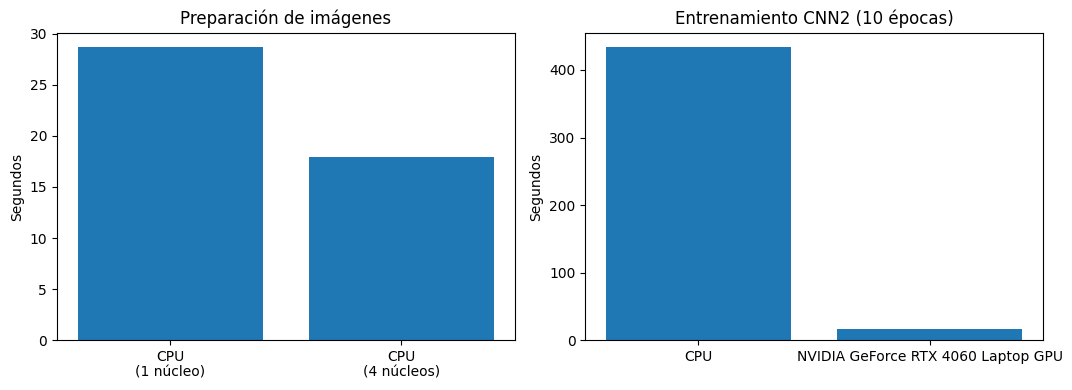

Speedup preparación de imágenes (CPU multi-núcleo vs. 1 núcleo): 1.60x
Speedup entrenamiento (GPU vs. CPU): 26.41x


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(
    ["CPU\n(1 núcleo)", "CPU\n(4 núcleos)"],
    [resultados["prep_cpu_secuencial_s"], resultados["prep_cpu_multinucleo_s"]],
)
axes[0].set_title("Preparación de imágenes")
axes[0].set_ylabel("Segundos")

axes[1].bar(
    ["CPU", resultados.get("gpu_nombre", "GPU (CUDA)")],
    [resultados["entrenamiento_cpu_s"], resultados["entrenamiento_gpu_s"]],
)
axes[1].set_title("Entrenamiento CNN2 (10 épocas)")
axes[1].set_ylabel("Segundos")

plt.tight_layout()
plt.savefig("../results/comparacion_tiempos.png", dpi=120)
plt.show()

print(f"Speedup preparación de imágenes (CPU multi-núcleo vs. 1 núcleo): {resultados['speedup_prep']:.2f}x")
print(f"Speedup entrenamiento (GPU vs. CPU): {resultados['speedup_entrenamiento']:.2f}x")

### Capturas de uso de recursos

Durante una corrida real de `python -m src.benchmark`:

- **CPU (fase de preparacion de imagenes):** el Administrador de Tareas muestra
  27% de uso de CPU total, con el proceso `Python (5)` (1 principal + 4
  workers del `multiprocessing.Pool`) usando 9.8% el solo, evidencia de que
  el trabajo se reparte entre varios procesos de CPU.

  ![CPU durante preparacion de imagenes](../results/captura_cpu_prep.jpg)

- **GPU (fase de entrenamiento):** `nvidia-smi` muestra el proceso
  `python.exe` corriendo en la GPU 0, con 38% de GPU-Util y 3231 MiB / 8188
  MiB de memoria de video en uso durante el entrenamiento con `device="cuda"`.

  ![GPU durante entrenamiento](../results/captura_gpu_train.jpg)


### Discusión técnica

**¿Por qué es más eficiente procesar las imágenes/archivos con los múltiples
núcleos del CPU y delegar exclusivamente la matemática de la red neuronal al
GPU?**

Porque son dos tipos de trabajo distintos. Leer y decodificar un JPEG,
redimensionarlo y normalizarlo es trabajo de **I/O y manipulación de
archivos**: cada imagen es independiente, pero la tarea en sí (llamadas al
sistema de archivos, decodificación JPEG en Pillow) no es aritmética masiva
que un GPU acelere — de hecho, mover cada imagen individualmente a GPU solo
para una normalización y traerla de vuelta sería más lento por el overhead
de transferencia PCIe que hacerlo en CPU. En cambio, entrenar la red es
**aritmética masivamente paralela y repetitiva** (millones de
multiplicaciones-acumulación en las convoluciones, iguales en estructura
para cada posición/filtro/imagen del batch): ahí sí paga tener miles de
núcleos CUDA ejecutando la misma operación sobre datos distintos. Por eso el
diseño separa el pipeline: CPU para preparar los datos una sola vez, GPU
para repetir la matemática del entrenamiento miles de veces.

**¿Cómo CUDA permitió reducir o cambiar el tiempo de procesamiento?**

El entrenamiento de 10 épocas de CNN2 pasó de **433.4 s en CPU** a
**16.4 s en GPU**, un speedup de **26.4x**. La razón es que
cada convolución reparte su cómputo entre miles de hilos CUDA en paralelo
(uno por elemento de salida), en vez de calcular esos elementos de forma
mayormente secuencial como hace la CPU; esto es consistente con la tabla de
operaciones repetitivas del Paso 1: el forward+backward se repite miles de
veces durante el entrenamiento, así que cualquier aceleración por repetición
se multiplica por esa cantidad de iteraciones.

**¿Qué factores justifican o limitan la utilización de CUDA?**

- *Tamaño del problema*: con pocas imágenes o un modelo muy pequeño, el
  overhead de transferir datos a GPU y lanzar kernels puede no compensar
  frente a correr en CPU; el beneficio de CUDA crece con el tamaño del
  dataset/modelo y con el número de épocas.
- *Memoria de GPU*: la RTX 4060 usada tiene 8GB de VRAM; con submuestras o
  modelos más grandes que no quepan en memoria, habría que usar batches más
  pequeños o streaming de datos, lo que reduce el beneficio.
- *Trabajo no paralelizable*: fases como la lectura de archivos no se
  benefician de CUDA (ver discusión anterior), así que el speedup total del
  pipeline completo está acotado por la Ley de Amdahl respecto a esas partes
  secuenciales.
- *Disponibilidad de hardware/drivers*: requiere una GPU NVIDIA con drivers
  y una build de PyTorch compiladas con soporte CUDA compatible; en Windows,
  frameworks como TensorFlow >2.10 no tienen esta opción de forma nativa.

### Conclusión

Separar el pipeline en una fase de preparación de imágenes (CPU,
multi-núcleo) y una fase de entrenamiento (GPU, CUDA vía PyTorch/cuDNN)
dio una mejora modesta en la primera fase (**1.6x**, limitada por I/O de
disco y por el overhead de lanzar procesos) y una mejora grande en la
segunda (**26.4x**), sin sacrificar exactitud: el modelo entrenado en GPU
llegó a 97.2% de exactitud en validación, consistente con el 96.3% que
reportó el Lab 3 original con Keras/TensorFlow. Esto confirma la hipótesis
de diseño del proyecto: la ganancia real de CUDA está en la matemática
masivamente paralela del entrenamiento, no en la manipulación de archivos,
y por eso el pipeline delega cada fase al hardware que mejor le queda.

Como trabajo futuro, se podría extender el benchmark a los otros modelos
del Lab 3 (Random Forest, red fully-connected) para comparar cuánto se
benefician de GPU frente a CNN2, o perfilar con `nvidia-smi`/`nsys` qué
porcentaje del tiempo en GPU es cómputo puro vs. transferencia de datos.